# Naive Ripple-Carry Quantum Adder (Out-of-Place)

This notebook implements a **naive ripple-carry adder** as our first
quantum arithmetic abstraction. The design is intentionally simple and
not optimized:

- It uses one **full-adder cell per bit**.
- Each full-adder cell uses:
  - 3 CNOTs to compute the sum bit, and
  - 3 Toffolis to compute the carry bit.
- It stores the sum in a separate register `s` (out-of-place adder).

Semantics (conceptual): for n-bit registers `x` and `y`, we build a circuit
that acts like

\begin{aligned}
  |x\rangle |y\rangle |0\rangle_{\text{cin}} |0\dots 0\rangle_{\text{cout}} |0\dots 0\rangle_{\text{s}}
  \;\longmapsto\;
  |x\rangle |y\rangle |0\rangle_{\text{cin}} |\text{carries}\rangle_{\text{cout}} |x+y\rangle_{\text{s}}.
\end{aligned}

Later, we can refine this into:
- an in-place adder (e.g., y <- x + y), and
- a more optimized construction (e.g., Cuccaro adder).

In [1]:
from dataclasses import dataclass

from qiskit import QuantumCircuit, QuantumRegister

@dataclass
class AdderResources:
    """Simple container for resource estimates of an n-bit adder.

    This is a first-order, approximate model corresponding to the
    naive ripple-carry adder implemented below.
    """
    n_bits: int
    toffoli_count: int
    cnot_count: int
    ancilla_count: int


def naive_ripple_adder_resources(n: int) -> AdderResources:
    """Return a rough resource estimate for the naive ripple-carry adder.

    Model:
      - Each bit uses ~3 Toffolis and ~3 CNOTs in its full-adder cell.
      - We allocate one carry ancilla per bit (in the `cout` register).

    This is not an optimized bound, but a simple, transparent starting point
    that matches the circuit structure implemented below.
    """
    toffoli_per_bit = 3
    cnot_per_bit = 3
    ancilla_per_bit = 1  # one carry ancilla in `cout`

    return AdderResources(
        n_bits=n,
        toffoli_count=toffoli_per_bit * n,
        cnot_count=cnot_per_bit * n,
        ancilla_count=ancilla_per_bit * n,
    )

In [2]:
def naive_full_adder_cell(
    circ: QuantumCircuit,
    x_qubit,
    y_qubit,
    cin_qubit,
    cout_qubit,
    s_qubit,
):
    """One-bit reversible full-adder cell.

    Conceptual behavior:
      - Inputs: x, y, cin, s=0, cout=0
      - Outputs:
          s    <- x ⊕ y ⊕ cin
          cout <- (x & y) ⊕ (x & cin) ⊕ (y & cin)

    We keep x, y, and cin unchanged. This is *not* an in-place adder;
    the sum is stored in a separate register `s`, and the carry is stored
    in `cout`.
    """
    # Sum bit into s: s = x ⊕ y ⊕ cin
    circ.cx(x_qubit, s_qubit)
    circ.cx(y_qubit, s_qubit)
    circ.cx(cin_qubit, s_qubit)

    # Carry-out into cout:
    # cout = (x & y) ⊕ (x & cin) ⊕ (y & cin)
    circ.ccx(x_qubit, y_qubit, cout_qubit)
    circ.ccx(x_qubit, cin_qubit, cout_qubit)
    circ.ccx(y_qubit, cin_qubit, cout_qubit)

In [3]:
def naive_ripple_adder_circuit(n: int) -> QuantumCircuit:
    """Construct a naive n-bit ripple-carry adder circuit (out-of-place).

    Registers (all size n except `cin`):
      - x:   input bits of the first addend
      - y:   input bits of the second addend (unchanged here)
      - cin: 1-qubit global carry-in (assumed initialized to |0>)
      - cout: n-qubit carry register (one ancilla per bit)
      - s:   n-qubit sum register (assumed initialized to |0...0>)

    Conceptual semantics:
      |x>|y>|0>_cin|0...0>_cout|0...0>_s
        → |x>|y>|0>_cin|carries>_cout|x+y>_s  (mod 2^n)

    This function does *not* perform any uncomputation of carries and
    is not optimized. It is intended as a first, transparent prototype
    of a ripple-carry quantum adder.
    """
    # Define registers
    x = QuantumRegister(n, "x")
    y = QuantumRegister(n, "y")
    cin = QuantumRegister(1, "cin")
    cout = QuantumRegister(n, "cout")
    s = QuantumRegister(n, "s")

    circ = QuantumCircuit(x, y, cin, cout, s)

    # For bit i:
    #   carry-in is cin[0] for i=0, otherwise cout[i-1]
    #   carry-out is cout[i]
    #   sum is written into s[i]
    for i in range(n):
        cin_qubit = cin[0] if i == 0 else cout[i - 1]
        cout_qubit = cout[i]
        s_qubit = s[i]

        naive_full_adder_cell(
            circ,
            x_qubit=x[i],
            y_qubit=y[i],
            cin_qubit=cin_qubit,
            cout_qubit=cout_qubit,
            s_qubit=s_qubit,
        )

    return circ

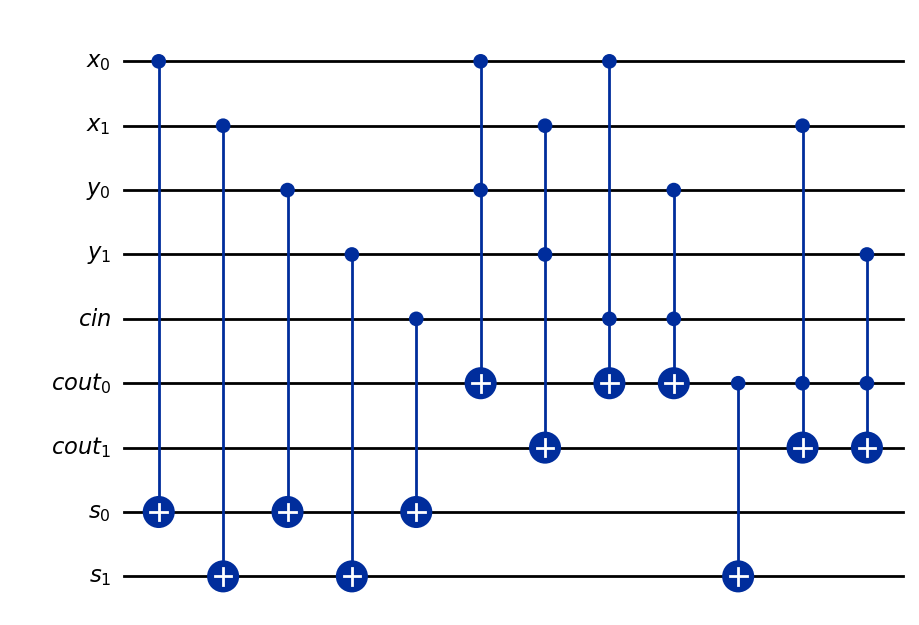


Resource estimate (model): AdderResources(n_bits=2, toffoli_count=6, cnot_count=6, ancilla_count=2)
Actual gate counts in circuit: ccx=6, cx=6


In [4]:
# Quick sanity check: build and inspect a small example

if __name__ == "__main__":
    n = 2
    circ = naive_ripple_adder_circuit(n)
    #print(circ)

    # Optionally visualize (in a notebook this will render nicely)
    try:
        display(circ.draw(output="mpl"))
    except Exception:
        # Fallback: text drawing if matplotlib or display isn't available
        print(circ.draw())

    # Print a simple resource estimate and compare with the model
    from qiskit.quantum_info import Operator

    resources = naive_ripple_adder_resources(n)
    print("\nResource estimate (model):", resources)

    # Count actual gates in the constructed circuit
    # Normalize the keys from circ.count_ops() to string names so .get(...) accepts string keys
    raw_counts = circ.count_ops()
    ops = {}
    for k, v in raw_counts.items():
        if isinstance(k, str):
            key = k
        else:
            # Instruction-like keys typically expose a 'name' attribute
            key = getattr(k, "name", str(k))
        ops[key] = v

    num_ccx = ops.get("ccx", 0)
    num_cx = ops.get("cx", 0)
    print(f"Actual gate counts in circuit: ccx={num_ccx}, cx={num_cx}")

In [5]:
from qiskit import ClassicalRegister
from qiskit_aer import AerSimulator
from qiskit import transpile

sim = AerSimulator()


def prepare_inputs(base_circ: QuantumCircuit, x_val: int, y_val: int, n: int) -> QuantumCircuit:
    """Return a circuit where |x_val> and |y_val> are prepared before running the adder."""
    prep = QuantumCircuit(*base_circ.qregs)

    x_reg = prep.qregs[0]  # x
    y_reg = prep.qregs[1]  # y

    # Set bits of x
    for i in range(n):
        if (x_val >> i) & 1:
            prep.x(x_reg[i])

    # Set bits of y
    for i in range(n):
        if (y_val >> i) & 1:
            prep.x(y_reg[i])

    # Run the ripple-carry adder after the inputs are prepared
    composed_circ = prep.compose(base_circ)
    # compose may be typed to return Optional[QuantumCircuit]; ensure it's not None for the declared return type
    assert composed_circ is not None
    return composed_circ


def run_case_sum_only(x_val: int, y_val: int, n: int = 2):
    base = naive_ripple_adder_circuit(n)
    qc = prepare_inputs(base, x_val, y_val, n)

    # Classical register layout: first n bits store the sum, the final bit stores cout
    c = ClassicalRegister(n + 1, "c")
    qc.add_register(c)

    s_reg = qc.qregs[4]
    cout_reg = qc.qregs[3]

    # Measure the sum (bit i -> classical bit i)
    for i in range(n):
        qc.measure(s_reg[i], c[i])

    # Measure the final carry-out (most-significant carry) into the last classical bit
    qc.measure(cout_reg[n - 1], c[n])

    tqc = transpile(qc, sim)
    result = sim.run(tqc, shots=1024).result()
    counts = result.get_counts()

    # There should be a single outcome; get its bitstring (drop register separators)
    bitstring = max(counts, key=counts.get).replace(" ", "")

    carry_bit = bitstring[0] if bitstring else "0"
    sum_bits = bitstring[1:] if len(bitstring) > 1 else ""

    sum_val = int(sum_bits, 2) if sum_bits else 0
    cout_val = int(carry_bit, 2)

    print(
        f"x = {x_val}, y = {y_val}  →  measured sum s = {sum_val} (bits {sum_bits}), "
        f"cout (final carry) = {cout_val} (bit {carry_bit})"
    )







In [ ]:
run_case_sum_only(10, 10, n=4)


x = 0, y = 0  →  measured sum s = 0 (bits 00), cout (final carry) = 0 (bit 0)
x = 0, y = 1  →  measured sum s = 1 (bits 01), cout (final carry) = 0 (bit 0)
x = 0, y = 2  →  measured sum s = 2 (bits 10), cout (final carry) = 0 (bit 0)
x = 0, y = 3  →  measured sum s = 3 (bits 11), cout (final carry) = 0 (bit 0)
x = 1, y = 0  →  measured sum s = 1 (bits 01), cout (final carry) = 0 (bit 0)
x = 1, y = 1  →  measured sum s = 2 (bits 10), cout (final carry) = 0 (bit 0)
x = 1, y = 2  →  measured sum s = 3 (bits 11), cout (final carry) = 0 (bit 0)
x = 1, y = 3  →  measured sum s = 0 (bits 00), cout (final carry) = 1 (bit 1)
x = 2, y = 0  →  measured sum s = 2 (bits 10), cout (final carry) = 0 (bit 0)
x = 2, y = 1  →  measured sum s = 3 (bits 11), cout (final carry) = 0 (bit 0)
x = 2, y = 2  →  measured sum s = 0 (bits 00), cout (final carry) = 1 (bit 1)
x = 2, y = 3  →  measured sum s = 1 (bits 01), cout (final carry) = 1 (bit 1)
x = 3, y = 0  →  measured sum s = 3 (bits 11), cout (final carry